# Dataset #1: Basketball-Reference Player Salaries by Team and Season (2014-15 to 2025-26)

Owner: Gian. Gives each player's salary by team and season, used for payroll share and roster info.

*Part of the COGS 108 data-cleaning pipeline. See [README.md](README.md) for how the six datasets fit together and the order to run the notebooks in.*

- **Dataset name:** Basketball-Reference, "Salaries" table on every team's season page
- **Link:** https://www.basketball-reference.com/teams/ (for example, the 2019-20 Warriors are at https://www.basketball-reference.com/teams/GSW/2020.html)
- **Saved as:** `data-files/00-raw/bbref_team_salaries_2015_2026.csv` (collected 11/6/2026)
- **Number of observations:** 7,863 rows
- **Number of variables:** 5
- **How we collected it:** We read Basketball-Reference's robots.txt on 11/4/2026. Team season pages are allowed, and the site asks for at least 3 seconds between requests. We used a short web scraping script (`modules/scrape_team_salaries.js`) that opened the page for each of the 30 teams in each of the 12 seasons (360 pages), waited 4 seconds between pages, and copied the "Salaries" table from each one. The page address gave us the team and the season, and the table gave us each player's Basketball-Reference ID, name, and salary. We stacked all 360 tables into one file. Doing this by hand would mean copying 360 tables one at a time, which is why we automated it. The script was written with help from Claude (see AI and Outside Help).

This dataset covers the salary and contract part of our research question. It tells us how much each player was paid by his team in each season, which lets us see how much of a team's payroll a player takes up and how long he stays with a team.

## 2A. Important variables, units, and what they mean

| Variable | Units | What it means |
|---|---|---|
| `season` | year (whole number) | The year the season **ends**, so `2015` is the 2014-15 season and `2026` is 2025-26. Basketball-Reference labels seasons this way, and it won't always match other datasets, which sometimes use the year a season starts. |
| `team` | text | Basketball-Reference's 3-letter team code (`GSW` = Golden State). Three codes differ from the usual ones: `BRK` = Brooklyn, `CHO` = Charlotte, and `PHO` = Phoenix. |
| `player_id` | text | Basketball-Reference's ID for the player (Stephen Curry = `curryst01`). This is a safer join key than a name, since names can be spelled differently on other websites. |
| `player` | text | The player's name. |
| `salary` | US dollars | What the team paid the player for that season. |

**What the values look like.** The highest salary in 2014-15 was 23.5 million. By 2025-26, it was 59.6 million (Stephen Curry), because the salary cap grew a lot over these years. Most players earn far less than the stars: the middle salary across all rows is about 2.4 million, since many bench players are on small or short deals. A salary of 0 or a blank means the table has no real salary listed for that row. We look into that in step 3D.

**Why salary matters for our question.** Salary lets us build two variables from our "ideal dataset": a player's share of his team's total salary (add up the salaries on a team and divide), and how long a player stays with a team (count the later seasons where he's still listed with that team). Our hypothesis says that players with less time left on their contract are more likely to be traded, since the team could lose them in free agency without getting anything back.

## 2B. Concerns with this dataset

1. **It doesn't say how long a contract lasts.** Each row only shows one season's pay. It has no contract length, years remaining, option years, or guaranteed money. We'll have to estimate years left ourselves by looking at which later seasons a player is still on the same team, and that doesn't work for 2025-26 because there's no later season in the data.
2. **A row is a salary line, not a unique player.** A player traded in the middle of a season appears once for each team, and a few players appear twice for the same team and season (for example, two short contracts). So we can't count rows as players. We check this in step 3C.
3. **The salary column is recorded differently over time.** Players with no real salary show up as `0` from 2018 to 2022 and as a blank from 2023 on. We explain this in step 3D.
4. **Names are spelled more than one way.** The same ID can have a plain and an accented spelling of the name, like Alex Abrines and Álex Abrines. If we match on names with other datasets, we'd lose these players, so we'll match on `player_id`.
5. **We don't know exactly who is listed.** Teams have between 15 and 45 rows in a season, but we haven't confirmed that every player who briefly played for a team shows up. Also, a website changes over time, so we record the date we collected it (11/6/2026).

## Setup

All file paths come from `nba_cleaning_utils.py`, which points at the `data-files/` folder (`RAW` = `00-raw/`, `INTERIM` = `01-interim/`, `PROCESSED` = `02-processed/`).

In [1]:
import os

import pandas as pd
import matplotlib.pyplot as plt

from nba_cleaning_utils import RAW, INTERIM, PROCESSED

## 3A. Load the data

In [2]:
salaries = pd.read_csv(RAW / 'bbref_team_salaries_2015_2026.csv')
salaries.head(10)

,season,team,player_id,player,salary
0,2015,ATL,horfoal01,Al Horford,12000000.0
1,2015,ATL,millspa01,Paul Millsap,9500000.0
2,2015,ATL,teaguje01,Jeff Teague,8000000.0
3,2015,ATL,korveky01,Kyle Korver,6253521.0
4,2015,ATL,sefolth01,Thabo Sefolosha,4150000.0
5,2015,ATL,scottmi01,Mike Scott,3333333.0
6,2015,ATL,carrode01,DeMarre Carroll,2442455.0
7,2015,ATL,macksh01,Shelvin Mack,2433333.0
8,2015,ATL,bazemke01,Kent Bazemore,2000000.0
9,2015,ATL,brandel01,Elton Brand,2000000.0


## 3B. Is the data tidy?

Tidy means each row is one observation and each column is one variable.

In [3]:
salaries.info()

<class 'pandas.DataFrame'>
RangeIndex: 7863 entries, 0 to 7862
Data columns (total 5 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   season     7863 non-null   int64  
 1   team       7863 non-null   str    
 2   player_id  7862 non-null   str    
 3   player     7862 non-null   str    
 4   salary     7301 non-null   float64
dtypes: float64(1), int64(1), str(3)
memory usage: 307.3 KB


In [4]:
# A traded or waived player can appear on two teams in the same season. Example: Damian Lillard
salaries[(salaries['player_id'] == 'lillada01') & (salaries['season'] >= 2024)]

,season,team,player_id,player,salary
6061,2024,MIL,lillada01,Damian Lillard,45640084.0
6781,2025,MIL,lillada01,Damian Lillard,48787676.0
7541,2026,MIL,lillada01,Damian Lillard,22516603.0
7720,2026,POR,lillada01,Damian Lillard,14104000.0


**What we found:**

- **The data is already tidy.** Each row is one salary line for a player on a team in a season, and each column holds one kind of information. It's already in "long" format (one row per player per season), so we don't need to reshape it.
- **The data types make sense.** `season` is a whole number, `team`, `player_id`, and `player` are text, and `salary` is `float64` (decimals) only because pandas stores blanks as `NaN`. The values are still whole dollars.
- **One row is not always one player.** In the table above, Damian Lillard has two rows in 2025-26, one for Milwaukee and one for Portland. We think Milwaukee still owed him money after waiving him while Portland signed him. This will matter when we count players and when we link salary to trades.

## 3C. Size of the data

In [5]:
print('rows, columns:', salaries.shape)
print('seasons:', salaries['season'].min(), 'to', salaries['season'].max(), '(end year, so 2015 = 2014-15)')
print('teams:', salaries['team'].nunique())
print('different players:', salaries['player_id'].nunique())

rows_per_team_season = salaries.groupby(['season', 'team']).size()
print('rows per team and season: min', rows_per_team_season.min(),
      ', median', rows_per_team_season.median(), ', max', rows_per_team_season.max())

rows, columns: (7863, 5)
seasons: 2015 to 2026 (end year, so 2015 = 2014-15)
teams: 30
different players: 1752
rows per team and season: min 15 , median 21.0 , max 45


In [6]:
rows_per_season = salaries.groupby('season').size()
rows_per_season

season
2015    563
2016    564
2017    610
2018    651
2019    625
2020    615
2021    614
2022    747
2023    684
2024    741
2025    712
2026    737
dtype: int64

We have 12 full seasons with all 30 teams in each one (360 team-seasons), which is 7,863 rows and about 1,750 different players. That's much more than the 100 observations we said we'd need for a predictive model. Each season has between 563 and 747 rows, so no season is missing or much smaller than the others.

Next we check whether the rows are really unique, since we said a row isn't always one player.

In [7]:
key = ['season', 'team', 'player_id']
same_key = salaries[salaries.duplicated(key, keep=False) & salaries['player_id'].notna()]

print('rows that share the same season, team, and player with another row:', len(same_key))
print('exact duplicate rows (every column the same):', salaries.duplicated().sum())

teams_per_player_season = salaries.groupby(['season', 'player_id'])['team'].nunique()
print('player-seasons on 2 or more teams:', (teams_per_player_season > 1).sum(),
      'out of', len(teams_per_player_season))

same_key.sort_values(key).head(10)

rows that share the same season, team, and player with another row: 452
exact duplicate rows (every column the same): 61
player-seasons on 2 or more teams: 529 out of 7023


,season,team,player_id,player,salary
117,2015,DAL,jamesbe01,Bernard James,915243.0
122,2015,DAL,jamesbe01,Bernard James,236866.0
182,2015,HOU,scolalu01,Luis Scola,6541000.0
183,2015,HOU,scolalu01,Luis Scola,6172538.0
540,2015,UTA,bostde01,Dee Bost,65000.0
541,2015,UTA,bostde01,Dee Bost,65000.0
5042,2023,BRK,brownmo01,Moses Brown,105522.0
5043,2023,BRK,brownmo01,Moses Brown,105522.0
5045,2023,BRK,dukeda01,David Duke,28241.0
5047,2023,BRK,dukeda01,David Duke,NaN


In [8]:
# Same ID, different spellings of the name
names_per_id = salaries.groupby('player_id')['player'].nunique()
print('player IDs with more than one spelling of the name:', (names_per_id > 1).sum())

salaries[salaries['player_id'].isin(['abrinal01', 'asikom01'])][['player_id', 'player']].drop_duplicates()

player IDs with more than one spelling of the name: 57


,player_id,player
331,asikom01,Omer Asik
1542,abrinal01,Alex Abrines
2473,asikom01,Ömer Aşık
2816,abrinal01,Álex Abrines


- **Players on two teams in one season are real information.** About 530 player-seasons have rows for 2 or more teams. Those are players who were traded (or waived and signed elsewhere) during that season, which is exactly the kind of event our question is about, so we keep them.
- **Some rows are copies or near-copies.** Of the rows that share the same season, team, and player, many are exact duplicates and the rest have different salaries or one blank salary (probably separate short contracts with the same team). We'll remove the exact copies in the cleaning step and decide how to combine the others.
- **57 player IDs have two spellings of the name** (for example, Alex Abrines and Álex Abrines). This is the reason we match on `player_id` and not on `player`.

## 3D. Missing data

In [9]:
salaries.isna().sum()

season         0
team           0
player_id      1
player         1
salary       562
dtype: int64

In [10]:
# The one row with no player ID or name
salaries[salaries['player_id'].isna()]

,season,team,player_id,player,salary
3156,2020,DAL,NaN,NaN,708426.0


In [11]:
status = pd.DataFrame({
    'rows': salaries.groupby('season').size(),
    'salary is 0': salaries[salaries['salary'] == 0].groupby('season').size(),
    'salary is blank': salaries[salaries['salary'].isna()].groupby('season').size()
}).fillna(0).astype(int)

status

,rows,salary is 0,salary is blank
season,,,
2015,563,0,1
2016,564,0,0
2017,610,0,0
2018,651,72,0
2019,625,47,0
2020,615,53,0
2021,614,63,0
2022,747,69,0
2023,684,0,110


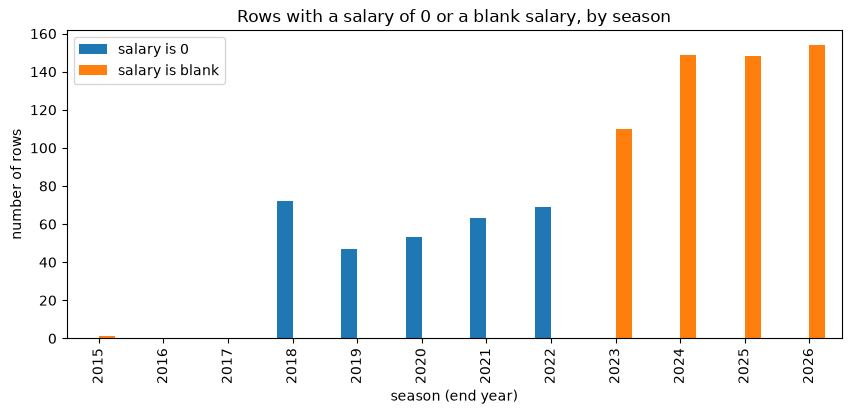

In [12]:
fig, ax = plt.subplots(figsize=(10, 4))
status[['salary is 0', 'salary is blank']].plot(kind='bar', ax=ax)
ax.set_xlabel('season (end year)')
ax.set_ylabel('number of rows')
ax.set_title('Rows with a salary of 0 or a blank salary, by season')
plt.show()

In [13]:
# Do the blank-salary rows belong to players who also have a real salary with that team that season?
blank = salaries[salaries['salary'].isna() & salaries['player_id'].notna()]
real = salaries[salaries['salary'] > 0][key].drop_duplicates()
blank_with_real = blank.merge(real, on=key, how='inner')

print(len(blank), 'blank-salary rows')
print(len(blank_with_real), 'of them are for a player who also has a salary above 0 with the same team that season')

562 blank-salary rows
123 of them are for a player who also has a salary above 0 with the same team that season


**What we found:**

- **`salary` is blank in 562 rows, and `player_id` and `player` are blank in 1 row.** Everything else is complete.
- **The blank and zero salaries are not random. They depend on the season.** Blanks appear almost only from 2023 to 2026 (about 16-21% of rows each season, and just 1 row before that). Zeros appear only from 2018 to 2022 (between 47 and 72 rows each season) and never in any other season. Since the two never overlap, they look like the same kind of row (probably players without a regular salary, such as two-way contracts) that Basketball-Reference shows as `0` in one period and as a blank in another. We can't confirm this from the data alone, so it's our best guess.
- **A blank doesn't mean a player was paid nothing.** Some blank rows belong to a player who also has a real salary with the same team that season, so the blank may just be an extra line. Because we're not sure what a blank or a zero means, we won't fill either one with a made-up number. We'll flag them and decide how to treat them in the cleaning step.
- **The row with no player ID is not a player.** It's a Dallas line from 2019-20 with a salary of 708,426 and no name. It may be a team-level item, like money still owed to a former player. We'll check it before removing it.

## 3E. Outliers and suspicious entries

We look for values that are extreme or don't make sense, then decide whether they're real or errors.

In [14]:
# The highest salary in each season
top_by_season = salaries.loc[salaries.groupby('season')['salary'].idxmax(), ['season', 'team', 'player', 'salary']]
top_by_season

,season,team,player,salary
235,2015,LAL,Kobe Bryant,23500000.0
800,2016,LAL,Kobe Bryant,25000000.0
1229,2017,CLE,LeBron James,30963450.0
1934,2018,GSW,Stephen Curry,34682550.0
2574,2019,GSW,Stephen Curry,37457154.0
3201,2020,GSW,Stephen Curry,40231758.0
3806,2021,GSW,Stephen Curry,43006362.0
4464,2022,GSW,Stephen Curry,45780966.0
5180,2023,GSW,Stephen Curry,48070014.0
5884,2024,GSW,Stephen Curry,51915615.0


In [15]:
# Very small salaries (above 0 but under $100,000)
small = salaries[(salaries['salary'] > 0) & (salaries['salary'] < 100000)]
print('rows with a salary between $1 and $99,999:', len(small))

print(small.groupby('season').size())
small.sample(8, random_state=1)

rows with a salary between $1 and $99,999: 488
season
2015    45
2016    47
2017    64
2018    44
2019    46
2020    23
2021    16
2022    92
2023    25
2024    28
2025    19
2026    39
dtype: int64


,season,team,player_id,player,salary
4815,2022,PHI,brownch02,Charlie Brown,95930.0
1272,2017,DAL,warneja01,Jameel Warney,20000.0
1868,2018,CLE,perkike01,Kendrick Perkins,13156.0
6118,2024,NOP,brockiz01,Izaiah Brockington,64343.0
5878,2024,DET,nowelja01,Jaylen Nowell,24885.0
1867,2018,CLE,thornma02,Marcus Thornton,46080.0
2553,2019,DEN,terryem01,Emanuel Terry,35000.0
1972,2018,HOU,canaais01,Isaiah Canaan,53465.0


In [16]:
# Teams with the most rows in one season
rows_per_team_season.sort_values(ascending=False).head(5)

season  team
2024    MEM     45
2026    MEM     40
        BRK     37
        IND     35
2025    TOR     35
dtype: int64

**What we found:**

- **The highest salaries are extreme but real.** The top salary each season belongs to a star (Kobe Bryant in 2014-15 and 2015-16, LeBron James in 2016-17, and Stephen Curry from 2017-18 on). It rises steadily from 23.5 million to 59.6 million, which fits the salary cap growing over time. We keep them, because they're the maximum-type contracts and not mistakes.
- **488 rows have a very small salary** (for example, 13,156 for Kendrick Perkins in 2017-18). That's far below what any player earns for a full season, so we think these are partial payments, like a short-term contract that only lasted a few days. They're real, but they could mislead us if we treated them as a full-season salary. We'll keep them and flag them.
- **2021-22 stands out.** It has the most rows (747), the most very small salaries (92), and the most players on 2 or more teams (75, compared to about 40 in most seasons). We think many teams signed short-term players that season, but we can't confirm the reason from this data.
- **The biggest rosters look believable.** Memphis in 2023-24 has 45 rows, probably because it used many short-term and two-way players. We keep it.
- **Entries we already found in 3C and 3D that need handling:** the row with no player ID, the 61 exact duplicate rows, and the 0 and blank salaries.

## 3F. Clean the data

We make a cleaned copy and keep the raw `salaries` table unchanged. Here is each choice and why we made it:

1. **Remove the row with no player ID.** It's not a player and we can't match it to anything. It's 1 row out of 7,863.
2. **Remove exact duplicate rows.** These are identical copies, so they carry no new information.
3. **Turn a salary of 0 into a blank.** In step 3D, zeros (2018-2022) and blanks (2023-2026) looked like the same thing recorded two ways, so we use one value for both. We **don't drop** these rows, because the player was still on that team that season and we need to know who was on each roster to study trades. We **don't fill them** with 0 or an average, because we don't know the real salary and a made-up number would hurt the analysis. Instead we add a column, `no_salary_listed`, that marks them.
4. **Keep one row per player, team, and season.** When a player has 2 or more rows for the same team and season, we keep the largest salary. We aren't sure what the extra lines mean (a second short contract, or money still owed), so adding them could count the same money twice. The column `n_salary_lines` shows how many rows were combined.
5. **Use one spelling of each name.** Each `player_id` gets the most recent spelling of the name.
6. **Add two helper columns:** `very_small_salary` (under 100,000, from step 3E) and `season_label` (like `2014-15`, so it's clear which season the end-year number means).

In [17]:
print('rows at the start:', len(salaries))

clean = salaries.copy()

# 1. remove the row with no player ID
clean = clean[clean['player_id'].notna()]
print('after removing the row with no player ID:', len(clean))

# 2. remove exact duplicate rows
clean = clean.drop_duplicates()
print('after removing exact duplicates:', len(clean))

# 3. a salary of 0 becomes a blank (NaN), so both kinds of "no salary" look the same
clean['salary'] = clean['salary'].mask(clean['salary'] == 0)

# 4. one row per player, team, and season (keep the largest salary)
n_lines = clean.groupby(key).size().rename('n_salary_lines')
clean = clean.groupby(key, as_index=False).agg(player=('player', 'last'), salary=('salary', 'max'))
clean = clean.merge(n_lines, on=key)
print('after one row per player, team, and season:', len(clean))

# 5. one spelling of each name (the most recent one)
latest_name = clean.sort_values('season').groupby('player_id')['player'].last()
clean['player'] = clean['player_id'].map(latest_name)

# 6. helper columns
clean['no_salary_listed'] = clean['salary'].isna()
clean['very_small_salary'] = clean['salary'] < 100000
clean['season_label'] = (clean['season'] - 1).astype(str) + '-' + (clean['season'] % 100).astype(str).str.zfill(2)

clean = clean[['season_label', 'season', 'team', 'player_id', 'player', 'salary',
               'n_salary_lines', 'no_salary_listed', 'very_small_salary']]
clean = clean.sort_values(['season', 'team', 'salary'], ascending=[True, True, False]).reset_index(drop=True)

clean.head(10)

rows at the start: 7863
after removing the row with no player ID: 7862
after removing exact duplicates: 7801
after one row per player, team, and season: 7615


,season_label,season,team,player_id,player,salary,n_salary_lines,no_salary_listed,very_small_salary
0,2014-15,2015,ATL,horfoal01,Al Horford,12000000.0,1,False,False
1,2014-15,2015,ATL,millspa01,Paul Millsap,9500000.0,1,False,False
2,2014-15,2015,ATL,teaguje01,Jeff Teague,8000000.0,1,False,False
3,2014-15,2015,ATL,korveky01,Kyle Korver,6253521.0,1,False,False
4,2014-15,2015,ATL,sefolth01,Thabo Sefolosha,4150000.0,1,False,False
5,2014-15,2015,ATL,scottmi01,Mike Scott,3333333.0,1,False,False
6,2014-15,2015,ATL,carrode01,DeMarre Carroll,2442455.0,1,False,False
7,2014-15,2015,ATL,macksh01,Shelvin Mack,2433333.0,1,False,False
8,2014-15,2015,ATL,bazemke01,Kent Bazemore,2000000.0,1,False,False
9,2014-15,2015,ATL,brandel01,Elton Brand,2000000.0,1,False,False


In [18]:
print('rows, columns:', clean.shape)
print('different players:', clean['player_id'].nunique())
print('rows that combined 2 or more lines:', (clean['n_salary_lines'] > 1).sum())
print('rows with no salary listed:', clean['no_salary_listed'].sum(),
      '(', round(100 * clean['no_salary_listed'].mean(), 1), '% )')
print('player IDs with more than one spelling of the name:', clean.groupby('player_id')['player'].nunique().gt(1).sum())

clean.isna().sum()

rows, columns: (7615, 9)
different players: 1752
rows that combined 2 or more lines: 176
rows with no salary listed: 733 ( 9.6 % )
player IDs with more than one spelling of the name: 0


season_label           0
season                 0
team                   0
player_id              0
player                 0
salary               733
n_salary_lines         0
no_salary_listed       0
very_small_salary      0
dtype: int64

**Result:** the cleaned table has 7,615 rows (down from 7,863) for the same 1,752 players, and every player ID now has one spelling of the name. About 9.6% of rows (733) still have no salary listed. We kept them on purpose and flagged them, so later we can decide whether to leave them out or handle them differently for each analysis.

## 3G. Save the cleaned data

The raw file stays in `data-files/00-raw/`. The cleaned version goes to `data-files/02-processed/`.

In [19]:
os.makedirs(PROCESSED, exist_ok=True)

clean.to_csv(PROCESSED / 'bbref_team_salaries_clean.csv', index=False)

# check that it saved correctly
check = pd.read_csv(PROCESSED / 'bbref_team_salaries_clean.csv')
print('saved file:', check.shape)
check.head()

saved file: (7615, 9)


,season_label,season,team,player_id,player,salary,n_salary_lines,no_salary_listed,very_small_salary
0,2014-15,2015,ATL,horfoal01,Al Horford,12000000.0,1,False,False
1,2014-15,2015,ATL,millspa01,Paul Millsap,9500000.0,1,False,False
2,2014-15,2015,ATL,teaguje01,Jeff Teague,8000000.0,1,False,False
3,2014-15,2015,ATL,korveky01,Kyle Korver,6253521.0,1,False,False
4,2014-15,2015,ATL,sefolth01,Thabo Sefolosha,4150000.0,1,False,False


When we combine this with our other datasets, we'll match on `player_id` and `season` (the end year of the season) and not on player names.

## 4. Summary statistics

These are the salary variables we plan to use in our model: how much players are paid, how much of a team's payroll they take up, and how many players change teams in a season.

In [20]:
# Salaries by season
by_season = clean.groupby('season_label')['salary'].agg(rows_with_salary='count', median_salary='median', top_salary='max')

table = by_season.copy()
table['median_salary'] = table['median_salary'].map('${:,.0f}'.format)
table['top_salary'] = table['top_salary'].map('${:,.0f}'.format)
table

,rows_with_salary,median_salary,top_salary
season_label,,,
2014-15,559,"$2,055,840","$23,500,000"
2015-16,564,"$2,100,000","$25,000,000"
2016-17,610,"$2,103,284","$30,963,450"
2017-18,579,"$2,319,360","$34,682,550"
2018-19,578,"$2,526,840","$37,457,154"
2019-20,561,"$2,686,560","$40,231,758"
2020-21,551,"$3,077,704","$43,006,362"
2021-22,678,"$2,281,140","$45,780,966"
2022-23,548,"$3,518,080","$48,070,014"


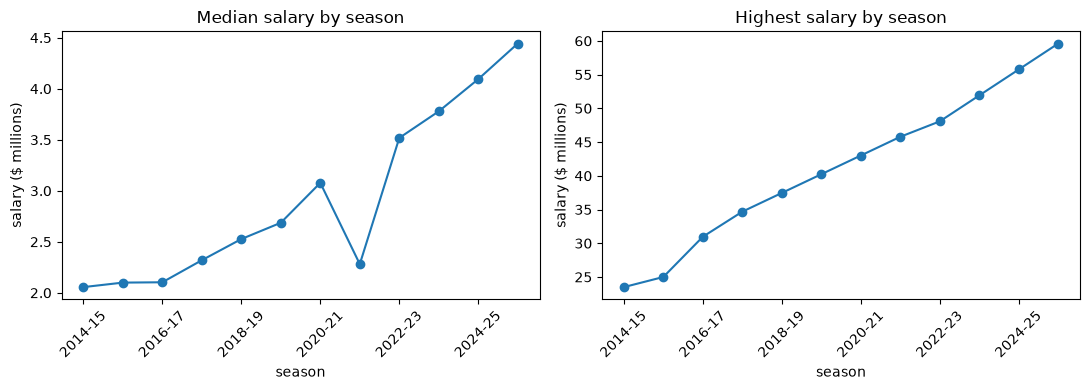

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

(by_season['median_salary'] / 1e6).plot(ax=axes[0], marker='o')
axes[0].set_title('Median salary by season')

(by_season['top_salary'] / 1e6).plot(ax=axes[1], marker='o')
axes[1].set_title('Highest salary by season')

for ax in axes:
    ax.set_xlabel('season')
    ax.set_ylabel('salary ($ millions)')
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

In [22]:
# Team payroll = the sum of the listed salaries on a team in a season
team_total = clean.groupby(['season', 'team'])['salary'].sum().rename('team_total')
payroll_by_season = team_total.groupby('season').median()
print('median team payroll by season ($ millions):')
print((payroll_by_season / 1e6).round(1))

# Each player's share of his team's payroll
with_share = clean.merge(team_total, on=['season', 'team'])
with_share['share_of_team'] = with_share['salary'] / with_share['team_total']

print()
print('share of team payroll, all players:')
print(with_share['share_of_team'].describe().round(3))

with_share.nlargest(5, 'share_of_team')[['season_label', 'team', 'player', 'salary', 'team_total', 'share_of_team']]

median team payroll by season ($ millions):
season
2015     74.4
2016     76.0
2017     98.9
2018    112.9
2019    122.1
2020    127.9
2021    128.6
2022    134.5
2023    148.9
2024    163.9
2025    169.9
2026    186.9
Name: team_total, dtype: float64

share of team payroll, all players:
count    6882.000
mean        0.052
std         0.065
min         0.000
25%         0.011
50%         0.023
75%         0.070
max         0.345
Name: share_of_team, dtype: float64


,season_label,team,player,salary,team_total,share_of_team
797,2015-16,LAL,Kobe Bryant,25000000.0,72415125.0,0.345232
4479,2021-22,HOU,John Wall,44310840.0,129096006.0,0.343239
2658,2018-19,LAL,LeBron James,35654150.0,107275731.0,0.332360
233,2014-15,LAL,Kobe Bryant,23500000.0,70914495.0,0.331385
4732,2021-22,OKC,Kemba Walker,26238422.0,80531607.0,0.325815


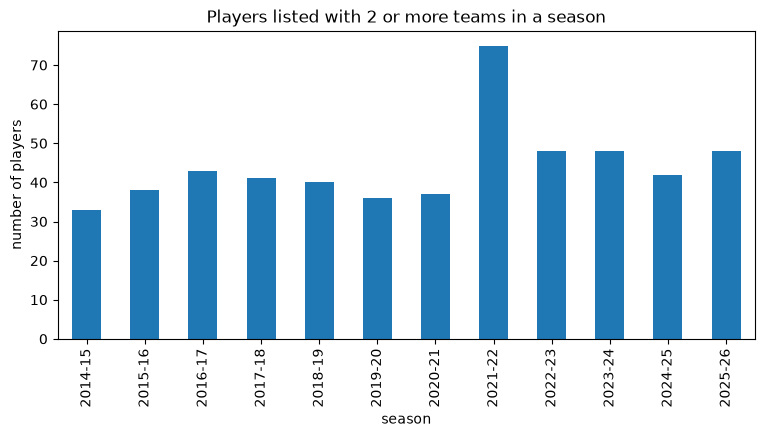

season_label
2014-15    33
2015-16    38
2016-17    43
2017-18    41
2018-19    40
2019-20    36
2020-21    37
2021-22    75
2022-23    48
2023-24    48
2024-25    42
2025-26    48
Name: team, dtype: int64

In [23]:
# Players who were on 2 or more teams in the same season
teams_per_player = clean.groupby(['season_label', 'player_id'])['team'].nunique()
two_or_more = (teams_per_player > 1).groupby('season_label').sum()

fig, ax = plt.subplots(figsize=(9, 4))
two_or_more.plot(kind='bar', ax=ax)
ax.set_xlabel('season')
ax.set_ylabel('number of players')
ax.set_title('Players listed with 2 or more teams in a season')
plt.show()

two_or_more

**What we found:**

- **Salaries have grown a lot.** The median salary roughly doubled, from about 2.1 million in 2014-15 to about 4.4 million in 2025-26, and the highest salary grew from 23.5 million to 59.6 million. The median dips in 2021-22 (about 2.3 million, compared to 3.1 million the season before) because that season has so many very small salaries.
- **Team payrolls grew too.** Adding up the listed salaries, the median team went from about 74 million in 2014-15 to about 187 million in 2025-26. This is the sum of listed salaries, so it's too low for teams with blank salaries and may not match the official payroll. We'll use it to estimate payroll, not as the exact number.
- **Most players take up a small share of their team's payroll.** The median player is about 2.3% of the team's total, but a star can take up much more: the largest share is Kobe Bryant in 2015-16, with 34.5% of the Lakers' listed payroll. This share is the "percentage of team salary" variable from our ideal dataset.
- **Players listed with 2 or more teams per season** is between 33 and 48 in most seasons (and 75 in 2021-22). It includes traded players and also players who were waived and signed elsewhere. It's a rough view of how many players change teams each season, not a count of trades, so we'll need a transaction dataset to find the actual trades.

Dataset #1 gives us salary, payroll share, and roster information for every season in our window (2014-15 to 2025-26). The cleaned table is saved in `data-files/02-processed/bbref_team_salaries_clean.csv`.